<a href="https://colab.research.google.com/github/RizkiHadiono/244107020198-Pembelajaran-Mesin/blob/main/JS14_244107020198_MOKHAMAD_RIZKI_HADIONO_SINGGIH.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# JS14 - Convolutional Neural Network

**Nama:** Mokhamad Rizki Hadiono Singgih  
**NIM:** 244107020198

Praktikum 1 klasifikasi Cat vs Dog, Praktikum 2 klasifikasi CIFAR-10, tugas modifikasi CIFAR-10, dan tugas CNN untuk MNIST.


In [ ]:
%matplotlib inline

import time
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.metrics import (confusion_matrix, classification_report,
                             accuracy_score, roc_curve, auc, roc_auc_score)

SEED = 42
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)
sns.set_theme(style='whitegrid')


## Fungsi bantu

Dipakai untuk menampilkan kurva pelatihan dan confusion matrix.


In [ ]:
def plot_history(history, judul='Kurva Pelatihan', figsize=(11, 4)):
    h = history.history if hasattr(history, 'history') else history
    epok = range(1, len(h['loss']) + 1)

    fig, ax = plt.subplots(1, 2, figsize=figsize)

    ax[0].plot(epok, h['loss'], marker='o', ms=3, label='latih')
    if 'val_loss' in h:
        ax[0].plot(epok, h['val_loss'], marker='o', ms=3, label='validasi')
    ax[0].set_title('Loss')
    ax[0].set_xlabel('Epoch')
    ax[0].legend()

    kunci = 'accuracy' if 'accuracy' in h else 'acc'
    ax[1].plot(epok, h[kunci], marker='o', ms=3, label='latih')
    if 'val_' + kunci in h:
        ax[1].plot(epok, h['val_' + kunci], marker='o', ms=3, label='validasi')
    ax[1].set_title('Akurasi')
    ax[1].set_xlabel('Epoch')
    ax[1].legend()

    fig.suptitle(judul)
    plt.tight_layout()
    plt.show()


def plot_confusion(y_true, y_pred, labels, judul, figsize=(7, 5.5), cmap='Blues'):
    cm = confusion_matrix(y_true, y_pred, labels=list(range(len(labels))))
    plt.figure(figsize=figsize)
    sns.heatmap(cm, annot=True, fmt='d', cmap=cmap, cbar=False,
                xticklabels=labels, yticklabels=labels)
    plt.xlabel('Prediksi')
    plt.ylabel('Label aktual')
    plt.title(judul)
    plt.tight_layout()
    plt.show()
    return cm


def hitung_waktu(fungsi):
    mulai = time.perf_counter()
    hasil = fungsi()
    return hasil, time.perf_counter() - mulai

# Praktikum 1 - Klasifikasi Cat vs Dog

## Langkah 1: Import Library

Jobsheet memakai dua import berikut:

```python
import tensorflow as tf
from keras.preprocessing.image import ImageDataGenerator
```

Kelas `ImageDataGenerator` sudah dihapus di Keras 3, jadi kode di atas langsung error `ImportError`. Penggantinya `image_dataset_from_directory` untuk membaca folder citra, ditambah layer augmentasi di dalam model.


In [ ]:
import tensorflow as tf
from tensorflow.keras.utils import image_dataset_from_directory


## Langkah 2: Menyiapkan Dataset

Folder `dataset` berisi `training_set`, `test_set`, dan `single_prediction`. Kalau folder belum ada, sel di bawah mengekstrak otomatis dari file ZIP di direktori kerja.


In [ ]:
DATA_DIR = Path('dataset')

if not (DATA_DIR / 'training_set').exists():
    kandidat = sorted(Path('.').glob('*.zip')) + sorted(Path('/content').glob('*.zip'))
    if not kandidat:
        try:
            from google.colab import files
            print('Silakan unggah dataset.zip')
            unggah = files.upload()
            kandidat = [Path(n) for n in unggah if n.lower().endswith('.zip')]
        except ImportError:
            print('Folder dataset tidak ditemukan dan bukan lingkungan Colab.')

    for berkas in kandidat:
        print('Mengekstrak', berkas)
        with zipfile.ZipFile(berkas) as z:
            for anggota in z.namelist():
                if anggota.startswith('__MACOSX') or anggota.endswith('.DS_Store'):
                    continue
                z.extract(anggota, '.')
        break

print('Folder training ada:', (DATA_DIR / 'training_set').exists())
print('Folder testing ada :', (DATA_DIR / 'test_set').exists())


Folder training ada: True
Folder testing ada : True


In [ ]:
def hitung_citra(folder):
    hasil = {}
    for kelas in sorted(p for p in Path(folder).iterdir() if p.is_dir()):
        hasil[kelas.name] = len(list(kelas.glob('*.jpg'))) + len(list(kelas.glob('*.png')))
    return hasil


info = pd.DataFrame([
    {'Bagian': 'training_set', **hitung_citra(DATA_DIR / 'training_set')},
    {'Bagian': 'test_set', **hitung_citra(DATA_DIR / 'test_set')},
])
display(info)

total_latih = int(info.loc[0, ['cats', 'dogs']].sum())
total_uji = int(info.loc[1, ['cats', 'dogs']].sum())
print(f'Total citra latih: {total_latih}')
print(f'Total citra uji  : {total_uji}')
print('Contoh nama berkas:', next((DATA_DIR / 'training_set' / 'cats').glob('*.jpg')).name)

,Bagian,cats,dogs
0,training_set,4000,4000
1,test_set,1000,1000


Total citra latih: 8000
Total citra uji  : 2000
Contoh nama berkas: cat.1.jpg


## Langkah 3: Pra Pengolahan Data

Pada jobsheet data latih memakai `rescale=1./255`, `shear_range=0.2`, `zoom_range=0.2`, dan `horizontal_flip=True`, sedangkan data uji hanya di-rescale. Di sini rescale dan augmentasi ditulis sebagai layer, lalu diterapkan hanya pada data latih.


In [ ]:
IMG_SIZE = (64, 64)
BATCH = 32

train_ds = image_dataset_from_directory(
    DATA_DIR / 'training_set',
    image_size=IMG_SIZE,
    batch_size=BATCH,
    label_mode='binary',
    shuffle=True,
    seed=SEED,
)

test_ds = image_dataset_from_directory(
    DATA_DIR / 'test_set',
    image_size=IMG_SIZE,
    batch_size=BATCH,
    label_mode='binary',
    shuffle=False,
)

nama_kelas = train_ds.class_names
print('Urutan kelas:', nama_kelas, '-> indeks 0 =', nama_kelas[0], ', indeks 1 =', nama_kelas[1])

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.cache().prefetch(AUTOTUNE)
test_ds = test_ds.cache().prefetch(AUTOTUNE)

# Data uji hanya di-rescale, tanpa augmentasi (setara test_datagen pada jobsheet)
rescale = layers.Rescaling(1. / 255)
test_ds_norm = test_ds.map(lambda x, y: (rescale(x), y),
                           num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)

print('Jumlah batch latih:', train_ds.cardinality().numpy())
print('Jumlah batch uji  :', test_ds.cardinality().numpy())
print('Nilai piksel data uji setelah rescale:',
      float(next(iter(test_ds_norm))[0].numpy().max()))

Found 8000 files belonging to 2 classes.


Found 2000 files belonging to 2 classes.


Urutan kelas: ['cats', 'dogs'] -> indeks 0 = cats , indeks 1 = dogs
Jumlah batch latih: 250
Jumlah batch uji  : 63
Nilai piksel data uji setelah rescale: 1.0


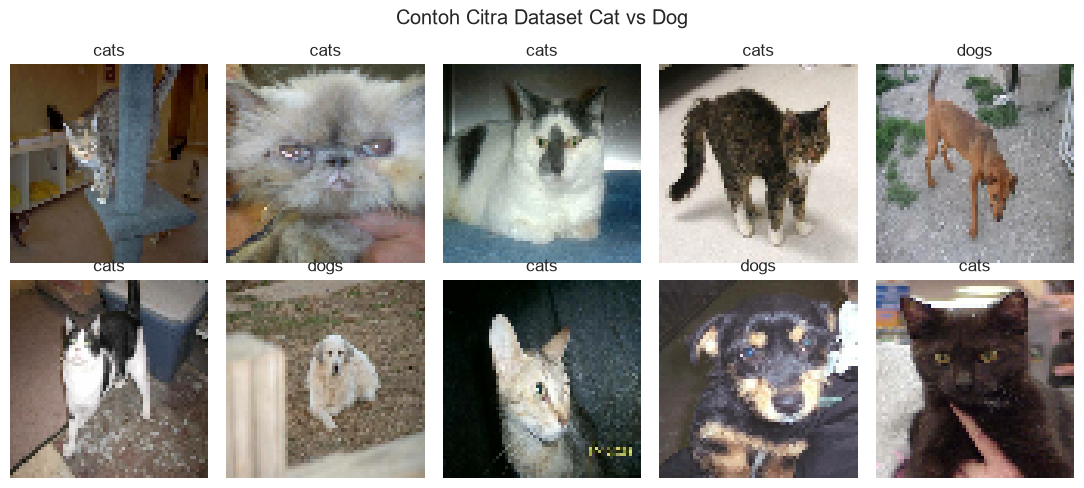

In [ ]:
plt.figure(figsize=(11, 5))
for gambar, label in train_ds.take(1):
    for i in range(10):
        ax = plt.subplot(2, 5, i + 1)
        plt.imshow(gambar[i].numpy().astype('uint8'))
        plt.title(nama_kelas[int(label[i][0])])
        plt.axis('off')
plt.suptitle('Contoh Citra Dataset Cat vs Dog')
plt.tight_layout()
plt.show()

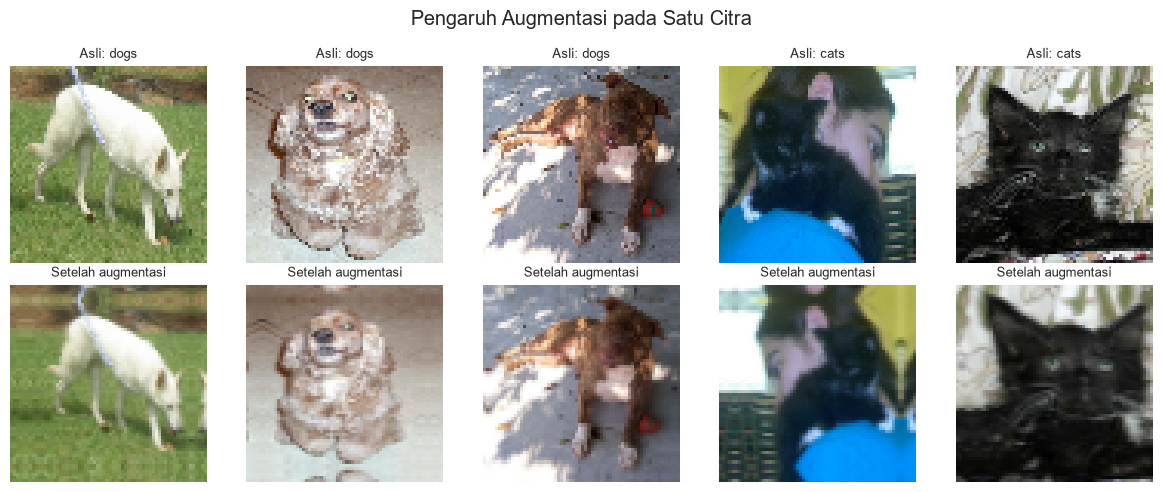

In [ ]:
# Augmentasi setara ImageDataGenerator pada jobsheet
data_augmentasi = keras.Sequential([
    layers.Rescaling(1. / 255),
    layers.RandomShear(0.2),
    layers.RandomZoom(0.2),
    layers.RandomFlip('horizontal'),
], name='augmentasi')

fig, ax = plt.subplots(2, 5, figsize=(12, 5))
for gambar, label in train_ds.take(1):
    for i in range(5):
        asli = gambar[i].numpy().astype('uint8')
        varian = data_augmentasi(gambar[i:i + 1])[0].numpy()
        ax[0, i].imshow(asli)
        ax[0, i].set_title(f'Asli: {nama_kelas[int(label[i][0])]}', fontsize=9)
        ax[0, i].axis('off')
        ax[1, i].imshow(varian)
        ax[1, i].set_title('Setelah augmentasi', fontsize=9)
        ax[1, i].axis('off')
plt.suptitle('Pengaruh Augmentasi pada Satu Citra')
plt.tight_layout()
plt.show()

## Langkah 4: Membuat Model CNN

Arsitektur mengikuti jobsheet: Conv2D 32 filter, max pooling, Conv2D 32 filter, max pooling, flatten, dense 128 dengan ReLU, lalu dense 1 dengan sigmoid. Loss yang dipakai binary crossentropy karena hanya ada dua kelas.


In [ ]:
tf.keras.utils.set_random_seed(SEED)

cnn = keras.Sequential([
    keras.Input(shape=(64, 64, 3)),
    layers.Conv2D(filters=32, kernel_size=3, activation='relu'),
    layers.MaxPool2D(pool_size=2, strides=2),
    layers.Conv2D(filters=32, kernel_size=3, activation='relu'),
    layers.MaxPool2D(pool_size=2, strides=2),
    layers.Flatten(),
    layers.Dense(units=128, activation='relu'),
    layers.Dense(units=1, activation='sigmoid'),
], name='cnn_jobsheet')

cnn.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
cnn.summary()

Model: "cnn_jobsheet"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 62, 62, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 31, 31, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 29, 29, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       802,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 813,217 (3.10 MB)

 Trainable params: 813,217 (3.10 MB)

 Non-trainable params: 0 (0.00 B)

## Langkah 5: Melatih Model

Model dilatih 25 epoch dengan data uji dipakai sebagai validasi, sama seperti jobsheet. Karena augmentasi sekarang berupa layer, data latih dilewatkan ke layer itu dulu sebelum masuk model.


In [ ]:
def latih_baseline():
    tf.keras.utils.set_random_seed(SEED)
    model = keras.Sequential([
        keras.Input(shape=(64, 64, 3)),
        layers.Conv2D(32, 3, activation='relu'),
        layers.MaxPool2D(2, 2),
        layers.Conv2D(32, 3, activation='relu'),
        layers.MaxPool2D(2, 2),
        layers.Flatten(),
        layers.Dense(128, activation='relu'),
        layers.Dense(1, activation='sigmoid'),
    ], name='cnn_baseline')
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

    # Augmentasi dan rescale hanya untuk data latih
    train_aug = train_ds.map(lambda x, y: (data_augmentasi(x, training=True), y),
                             num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)

    h = model.fit(train_aug, validation_data=test_ds_norm, epochs=25,
                  shuffle=False, verbose=2)
    return model, h


(cnn, hist_cnn), waktu_baseline = hitung_waktu(latih_baseline)
print(f'Waktu pelatihan: {waktu_baseline:.1f} detik')


Epoch 1/25


250/250 - 8s - 33ms/step - accuracy: 0.6150 - loss: 0.6498 - val_accuracy: 0.6920 - val_loss: 0.5870


Epoch 2/25


250/250 - 5s - 22ms/step - accuracy: 0.6976 - loss: 0.5825 - val_accuracy: 0.7115 - val_loss: 0.5550


Epoch 3/25


250/250 - 5s - 22ms/step - accuracy: 0.7243 - loss: 0.5402 - val_accuracy: 0.7425 - val_loss: 0.5225


... (41 outputs left out)

250/250 - 5s - 22ms/step - accuracy: 0.8432 - loss: 0.3635 - val_accuracy: 0.8120 - val_loss: 0.4359


Epoch 25/25


250/250 - 5s - 22ms/step - accuracy: 0.8496 - loss: 0.3489 - val_accuracy: 0.8045 - val_loss: 0.4476


Waktu pelatihan: 140.0 detik


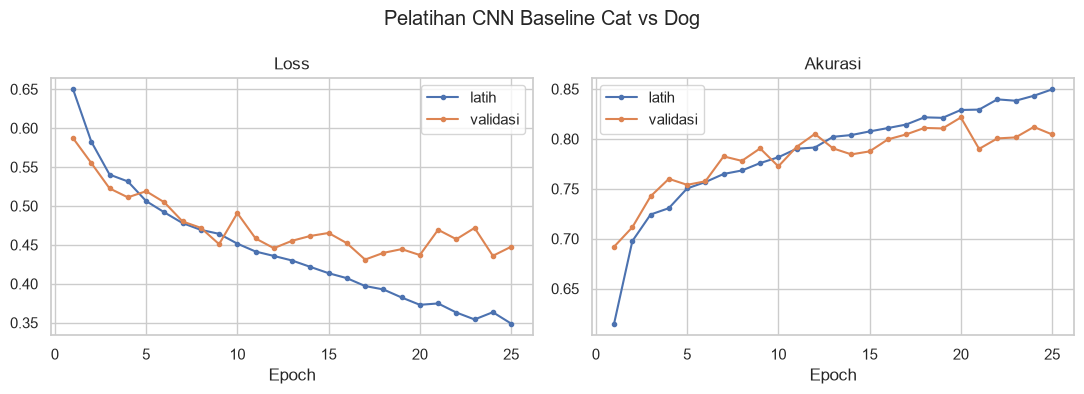

In [ ]:
plot_history(hist_cnn.history, 'Pelatihan CNN Baseline Cat vs Dog')

## Langkah 6: Evaluasi Model

Selain akurasi, ditampilkan confusion matrix, laporan klasifikasi, dan kurva ROC.


In [ ]:
loss_uji, acc_uji = cnn.evaluate(test_ds_norm, verbose=0)
print(f'Loss data uji    : {loss_uji:.4f}')
print(f'Akurasi data uji : {acc_uji:.4f}')

y_true, y_prob = [], []
for gambar, label in test_ds_norm:
    y_prob.extend(cnn.predict(gambar, verbose=0).ravel())
    y_true.extend(label.numpy().ravel())

y_true = np.array(y_true).astype(int)
y_prob = np.array(y_prob)
y_pred = (y_prob >= 0.5).astype(int)

print()
print(classification_report(y_true, y_pred, target_names=nama_kelas, digits=4))

Loss data uji    : 0.4476
Akurasi data uji : 0.8045



              precision    recall  f1-score   support

        cats     0.8264    0.7710    0.7977      1000
        dogs     0.7854    0.8380    0.8108      1000

    accuracy                         0.8045      2000
   macro avg     0.8059    0.8045    0.8043      2000
weighted avg     0.8059    0.8045    0.8043      2000



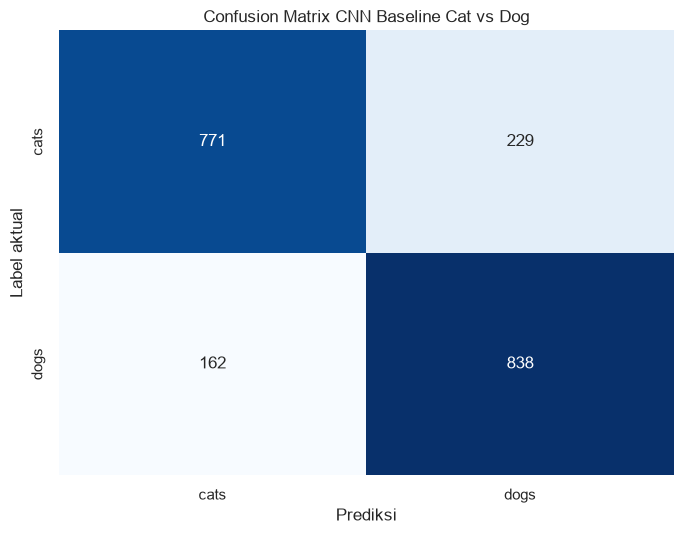

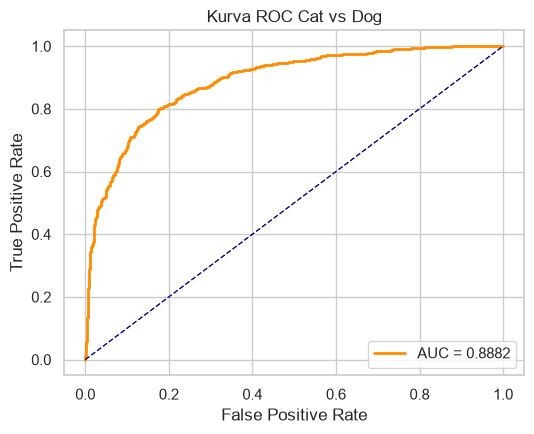

In [ ]:
cm_cnn = plot_confusion(y_true, y_pred, nama_kelas,
                        'Confusion Matrix CNN Baseline Cat vs Dog')

fpr, tpr, _ = roc_curve(y_true, y_prob)
nilai_auc = auc(fpr, tpr)

plt.figure(figsize=(5.5, 4.5))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'AUC = {nilai_auc:.4f}')
plt.plot([0, 1], [0, 1], 'navy', lw=1, linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Kurva ROC Cat vs Dog')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

## Langkah 7: Prediksi Satu Citra

Nilai sigmoid di atas 0.5 dibaca sebagai dog, di bawah 0.5 sebagai cat.


Berkas ditemukan: ['cat_or_dog_1.jpg', 'cat_or_dog_2.jpg']


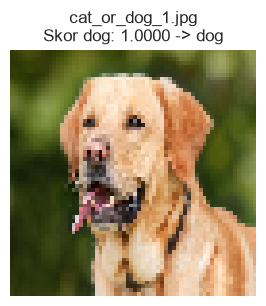

cat_or_dog_1.jpg: skor 1.0000, prediksi dog


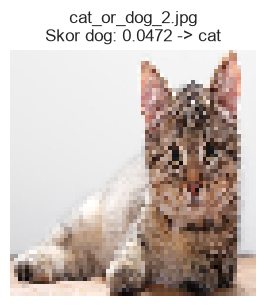

cat_or_dog_2.jpg: skor 0.0472, prediksi cat


In [ ]:
folder_prediksi = DATA_DIR / 'single_prediction'
berkas_uji = sorted(list(folder_prediksi.glob('*.jpg')) + list(folder_prediksi.glob('*.png')))
print('Berkas ditemukan:', [b.name for b in berkas_uji])

for berkas in berkas_uji:
    gambar = keras.utils.load_img(berkas, target_size=IMG_SIZE)
    array = keras.utils.img_to_array(gambar)
    array = np.expand_dims(array, axis=0) / 255.0

    hasil = float(cnn.predict(array, verbose=0)[0][0])
    prediksi = 'dog' if hasil >= 0.5 else 'cat'

    plt.figure(figsize=(3.2, 3.2))
    plt.imshow(gambar)
    plt.title(f'{berkas.name}\nSkor dog: {hasil:.4f} -> {prediksi}')
    plt.axis('off')
    plt.show()
    print(f'{berkas.name}: skor {hasil:.4f}, prediksi {prediksi}')

## Pembahasan

Model baseline mendapat akurasi 0.8045 pada data uji dengan loss 0.4476. Recall kucing 0.7710 dan recall anjing 0.8380, jadi model lebih sering salah pada kucing. Kemungkinan karena bentuk dan posisi kucing pada data latih lebih beragam dibanding anjing.

Akurasi latih 0.8496 dan akurasi uji 0.8045, selisihnya 0.0451. Selisih ini masih wajar untuk pelatihan 25 epoch tanpa batch normalization, tetapi sudah terlihat tanda model mulai menghafal data latih. Hampir semua parameter ada di blok dense: lapisan konvolusi hanya memakai 10.144 parameter, sedangkan sisanya 803.073 parameter ada di dua lapisan dense.

Kedua citra di folder `single_prediction` berhasil diprediksi dengan benar. `cat_or_dog_1.jpg` mendapat skor dog 1.0000 dan `cat_or_dog_2.jpg` mendapat skor 0.0472 sehingga dibaca sebagai cat.


# Praktikum 2 - Klasifikasi CIFAR-10

CIFAR-10 berisi 60.000 citra berwarna 32 x 32 piksel dengan 10 kelas, 50.000 untuk latih dan 10.000 untuk uji.

## Langkah 1: Load Library


In [ ]:
import tensorflow as tf
from tensorflow.keras import datasets, layers, models
import matplotlib.pyplot as plt


## Langkah 2: Unduh Dataset CIFAR-10

Nilai piksel 0 sampai 255 dinormalisasi menjadi 0 sampai 1.


In [ ]:
(train_images, train_labels), (test_images, test_labels) = datasets.cifar10.load_data()

train_images, test_images = train_images / 255.0, test_images / 255.0

print('Bentuk data latih:', train_images.shape)
print('Bentuk data uji  :', test_images.shape)
print('Rentang piksel   :', train_images.min(), 'sampai', train_images.max())

Bentuk data latih: (50000, 32, 32, 3)
Bentuk data uji  : (10000, 32, 32, 3)
Rentang piksel   : 0.0 sampai 1.0


## Langkah 3: Verifikasi Data

25 citra pertama ditampilkan untuk memastikan data dan label terbaca benar.


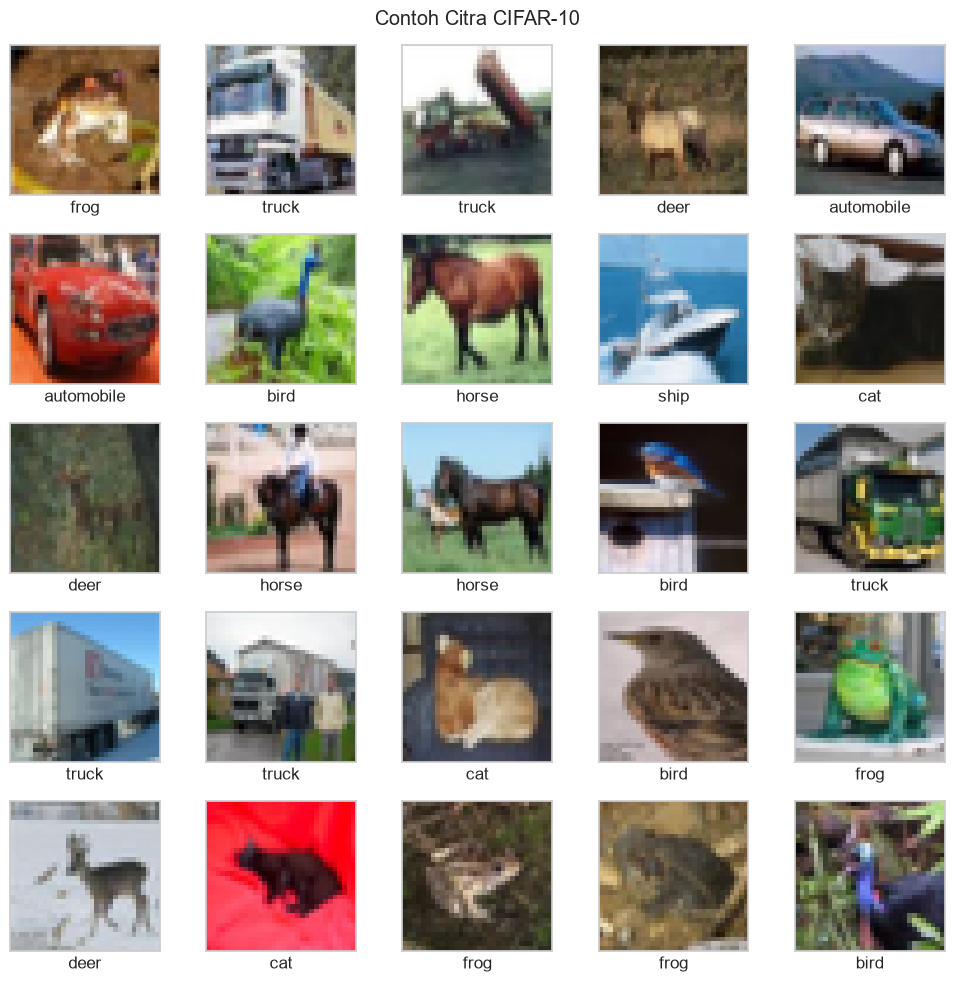

Jumlah citra per kelas pada data latih:
airplane      5000
automobile    5000
bird          5000
cat           5000
deer          5000
dog           5000
frog          5000
horse         5000
ship          5000
truck         5000


In [ ]:
class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer',
               'dog', 'frog', 'horse', 'ship', 'truck']

plt.figure(figsize=(10, 10))
for i in range(25):
    plt.subplot(5, 5, i + 1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(train_images[i])
    plt.xlabel(class_names[train_labels[i][0]])
plt.suptitle('Contoh Citra CIFAR-10')
plt.tight_layout()
plt.show()

distribusi = pd.Series(train_labels.ravel()).value_counts().sort_index()
distribusi.index = [class_names[i] for i in distribusi.index]
print('Jumlah citra per kelas pada data latih:')
print(distribusi.to_string())

## Langkah 4: Membuat Model CNN

Tiga lapisan konvolusi dengan filter 32, 64, dan 64, dua max pooling, lalu blok fully connected. Model dibangun bertahap supaya bentuk keluaran tiap lapisan bisa dilihat dari `model.summary()`.


In [ ]:
tf.keras.utils.set_random_seed(SEED)

model = models.Sequential()
model.add(layers.Input(shape=(32, 32, 3)))
model.add(layers.Conv2D(32, (3, 3), activation='relu'))
model.add(layers.MaxPooling2D((2, 2)))
model.add(layers.Conv2D(64, (3, 3), activation='relu'))
model.add(layers.MaxPooling2D((2, 2)))
model.add(layers.Conv2D(64, (3, 3), activation='relu'))

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_10 (Conv2D)              │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 4, 4, 64)       │        36,928 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 56,320 (220.00 KB)

 Trainable params: 56,320 (220.00 KB)

 Non-trainable params: 0 (0.00 B)

Setelah dua max pooling, bentuk keluaran menjadi 4 x 4 x 64 sehingga flatten menghasilkan 1.024 nilai. Lapisan dense 64 dengan ReLU menjadi hidden layer, lalu dense 10 tanpa aktivasi sebagai output. Softmax tidak dipakai karena loss-nya `SparseCategoricalCrossentropy(from_logits=True)` yang menerima skor mentah.


In [ ]:
model.add(layers.Flatten())
model.add(layers.Dense(64, activation='relu'))
model.add(layers.Dense(10))

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_10 (Conv2D)              │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 4, 4, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 64)             │        65,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 122,570 (478.79 KB)

 Trainable params: 122,570 (478.79 KB)

 Non-trainable params: 0 (0.00 B)

## Langkah 4.5: Compile Model

Optimizer Adam dengan loss sparse categorical crossentropy dan metrik akurasi.


In [ ]:
model.compile(optimizer='adam',
              loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
              metrics=['accuracy'])


## Langkah 5: Melatih Model

Pelatihan 10 epoch dengan data uji sebagai validasi.


In [ ]:
def latih_cifar_baseline():
    h = model.fit(train_images, train_labels, epochs=10,
                  validation_data=(test_images, test_labels), verbose=2)
    return h


hist_cifar, waktu_cifar = hitung_waktu(latih_cifar_baseline)
print(f'Waktu pelatihan: {waktu_cifar:.1f} detik')

Epoch 1/10


1563/1563 - 15s - 9ms/step - accuracy: 0.4576 - loss: 1.4884 - val_accuracy: 0.5779 - val_loss: 1.1796


Epoch 2/10


1563/1563 - 12s - 8ms/step - accuracy: 0.6072 - loss: 1.1121 - val_accuracy: 0.6394 - val_loss: 1.0220


Epoch 3/10


1563/1563 - 12s - 8ms/step - accuracy: 0.6611 - loss: 0.9649 - val_accuracy: 0.6622 - val_loss: 0.9782


... (11 outputs left out)

1563/1563 - 12s - 8ms/step - accuracy: 0.7889 - loss: 0.6031 - val_accuracy: 0.6752 - val_loss: 1.0528


Epoch 10/10


1563/1563 - 13s - 8ms/step - accuracy: 0.8020 - loss: 0.5677 - val_accuracy: 0.6640 - val_loss: 1.1263


Waktu pelatihan: 128.1 detik


## Langkah 6: Evaluasi Model

Kurva akurasi latih dan validasi ditampilkan, lalu model dievaluasi pada data uji.


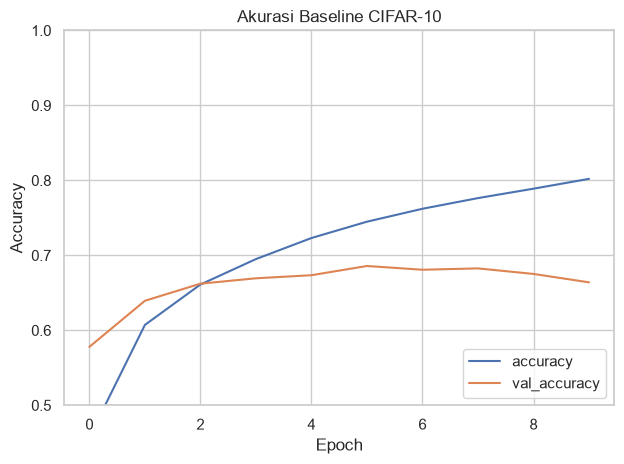

313/313 - 1s - 4ms/step - accuracy: 0.6640 - loss: 1.1263


In [ ]:
plt.plot(hist_cifar.history['accuracy'], label='accuracy')
plt.plot(hist_cifar.history['val_accuracy'], label='val_accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.ylim([0.5, 1])
plt.legend(loc='lower right')
plt.title('Akurasi Baseline CIFAR-10')
plt.tight_layout()
plt.show()

test_loss, test_acc = model.evaluate(test_images, test_labels, verbose=2)

## Langkah 7: Cetak Hasil Akurasi

Berapa akurasi yang didapat, dijawab pada sel berikut.


In [ ]:
print(f'Akurasi data uji   : {test_acc:.4f}')
print(f'Akurasi data latih : {hist_cifar.history["accuracy"][-1]:.4f}')
print(f'Akurasi validasi   : {hist_cifar.history["val_accuracy"][-1]:.4f}')
print(f'Loss data uji      : {test_loss:.4f}')
print()
print(f'Selisih akurasi latih dan uji: '
      f'{hist_cifar.history["accuracy"][-1] - test_acc:.4f}')

Akurasi data uji   : 0.6640
Akurasi data latih : 0.8020
Akurasi validasi   : 0.6640
Loss data uji      : 1.1263

Selisih akurasi latih dan uji: 0.1380


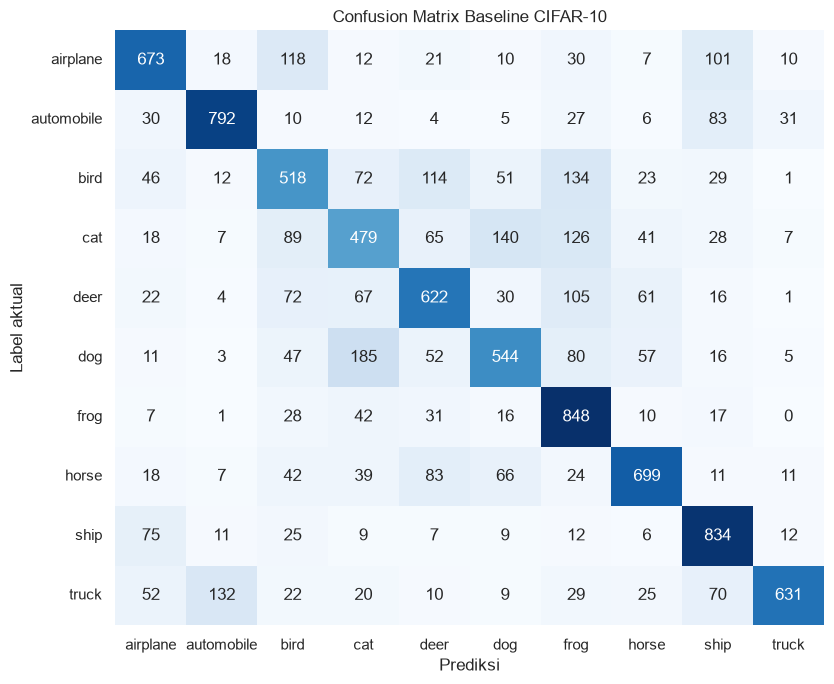

,Kelas,Akurasi per kelas,Jumlah benar,Jumlah sampel
6,frog,0.848,848,1000
8,ship,0.834,834,1000
1,automobile,0.792,792,1000
7,horse,0.699,699,1000
0,airplane,0.673,673,1000
9,truck,0.631,631,1000
4,deer,0.622,622,1000
5,dog,0.544,544,1000
2,bird,0.518,518,1000
3,cat,0.479,479,1000


In [ ]:
proba_cifar = tf.nn.softmax(model.predict(test_images, verbose=0)).numpy()
pred_cifar = proba_cifar.argmax(axis=1)

cm_cifar = plot_confusion(test_labels.ravel(), pred_cifar, class_names,
                          'Confusion Matrix Baseline CIFAR-10',
                          figsize=(8.5, 7), cmap='Blues')

akurasi_kelas = cm_cifar.diagonal() / cm_cifar.sum(axis=1)
tabel_kelas = pd.DataFrame({
    'Kelas': class_names,
    'Akurasi per kelas': akurasi_kelas,
    'Jumlah benar': cm_cifar.diagonal(),
    'Jumlah sampel': cm_cifar.sum(axis=1),
}).sort_values('Akurasi per kelas', ascending=False)
display(tabel_kelas.round(4))

## Pembahasan

Akurasi data uji 0.6640, sedangkan akurasi latih 0.8020. Selisih 0.1380 cukup besar dan loss data uji naik lagi di epoch terakhir menjadi 1.1263, jadi model mulai menghafal data latih.

Kelas yang paling mudah dikenali adalah frog (0.848) dan ship (0.834), karena latar keduanya cukup khas. Kelas yang paling sulit cat (0.479) dan bird (0.518). Pada resolusi 32 x 32 tekstur bulu kucing tidak terlihat sehingga sering tertukar dengan dog (0.544) dan deer (0.622), sedangkan bird sering tertukar dengan airplane karena sama-sama sering muncul di latar langit.

## Tugas 1: Modifikasi Model agar Akurasi Uji di Atas 80 Persen

Yang diubah dari model baseline:

1. Batch normalization setelah setiap konvolusi.
2. Padding `same` supaya informasi di tepi citra tidak hilang.
3. Augmentasi flip horizontal, translasi, dan zoom.
4. Dropout di blok fully connected dan penurunan learning rate otomatis.

Arsitektur tetap CNN sederhana, bukan model pretrained, supaya masih sebanding dengan baseline.


In [ ]:
data_augmentasi_cifar = keras.Sequential([
    layers.RandomFlip('horizontal'),
    layers.RandomTranslation(0.1, 0.1),
    layers.RandomZoom(0.1),
], name='augmentasi_cifar')


def blok_konvolusi(x, filter_):
    x = layers.Conv2D(filter_, 3, padding='same', use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.Conv2D(filter_, 3, padding='same', use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    return layers.MaxPooling2D(2)(x)


def buat_model_cifar_v2():
    tf.keras.utils.set_random_seed(SEED)
    masukan = keras.Input(shape=(32, 32, 3))
    x = data_augmentasi_cifar(masukan)

    x = blok_konvolusi(x, 32)
    x = blok_konvolusi(x, 64)
    x = blok_konvolusi(x, 128)

    x = layers.Flatten()(x)
    x = layers.Dropout(0.4)(x)
    x = layers.Dense(128, activation='relu')(x)
    x = layers.Dropout(0.3)(x)
    keluaran = layers.Dense(10)(x)

    model = keras.Model(masukan, keluaran, name='cnn_cifar_v2')
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-3),
        loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
        metrics=['accuracy'],
    )
    return model


model_v2 = buat_model_cifar_v2()
model_v2.summary()

Model: "cnn_cifar_v2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_6 (InputLayer)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentasi_cifar (Sequential)   │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 32, 32, 32)     │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 32, 32, 32)     │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_15 (Conv2D)              │ (None, 16, 16, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_16 (Conv2D)              │ (None, 16, 16, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_17 (Conv2D)              │ (None, 8, 8, 128)      │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_18 (Conv2D)              │ (None, 8, 8, 128)      │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_5 (Activation)       │ (None, 8, 8, 128)      │             

 Total params: 551,914 (2.11 MB)

 Trainable params: 551,018 (2.10 MB)

 Non-trainable params: 896 (3.50 KB)

In [ ]:
def latih_cifar_v2():
    callback = [
        keras.callbacks.EarlyStopping(monitor='val_accuracy', patience=6,
                                      restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5,
                                          patience=3, min_lr=1e-5, verbose=1),
    ]
    h = model_v2.fit(train_images, train_labels, epochs=30, batch_size=64,
                     validation_data=(test_images, test_labels),
                     callbacks=callback, verbose=2)
    return h


hist_v2, waktu_v2 = hitung_waktu(latih_cifar_v2)
print(f'Waktu pelatihan: {waktu_v2:.1f} detik')

Epoch 1/30


782/782 - 63s - 80ms/step - accuracy: 0.3990 - loss: 1.6357 - val_accuracy: 0.4335 - val_loss: 1.5317 - learning_rate: 0.0010


Epoch 2/30


782/782 - 59s - 75ms/step - accuracy: 0.5497 - loss: 1.2564 - val_accuracy: 0.5878 - val_loss: 1.1673 - learning_rate: 0.0010


Epoch 3/30


782/782 - 59s - 75ms/step - accuracy: 0.6197 - loss: 1.0848 - val_accuracy: 0.6673 - val_loss: 0.9601 - learning_rate: 0.0010


... (54 outputs left out)

782/782 - 58s - 74ms/step - accuracy: 0.8917 - loss: 0.3208 - val_accuracy: 0.8676 - val_loss: 0.4144 - learning_rate: 1.2500e-04


Epoch 30/30


782/782 - 58s - 74ms/step - accuracy: 0.8916 - loss: 0.3194 - val_accuracy: 0.8743 - val_loss: 0.3966 - learning_rate: 1.2500e-04


Waktu pelatihan: 1780.7 detik


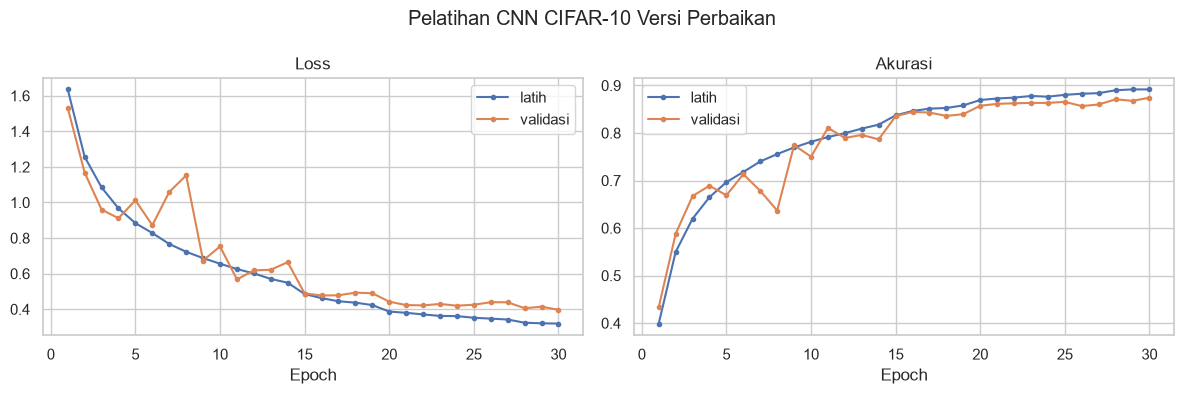

In [ ]:
plot_history(hist_v2.history, 'Pelatihan CNN CIFAR-10 Versi Perbaikan', figsize=(12, 4))

In [ ]:
loss_v2, acc_v2 = model_v2.evaluate(test_images, test_labels, verbose=0)
print(f'Loss data uji    : {loss_v2:.4f}')
print(f'Akurasi data uji : {acc_v2:.4f}')
print()
print(classification_report(test_labels.ravel(),
                            model_v2.predict(test_images, verbose=0).argmax(axis=1),
                            target_names=class_names, digits=4))


Loss data uji    : 0.3966
Akurasi data uji : 0.8743



              precision    recall  f1-score   support

    airplane     0.9042    0.8590    0.8810      1000
  automobile     0.9169    0.9600    0.9380      1000
        bird     0.7981    0.8260    0.8118      1000
         cat     0.7802    0.7630    0.7715      1000
        deer     0.8497    0.8760    0.8626      1000
         dog     0.8544    0.7920    0.8220      1000
        frog     0.8680    0.9140    0.8904      1000
       horse     0.9149    0.9030    0.9089      1000
        ship     0.9256    0.9460    0.9357      1000
       truck     0.9320    0.9040    0.9178      1000

    accuracy                         0.8743     10000
   macro avg     0.8744    0.8743    0.8740     10000
weighted avg     0.8744    0.8743    0.8740     10000



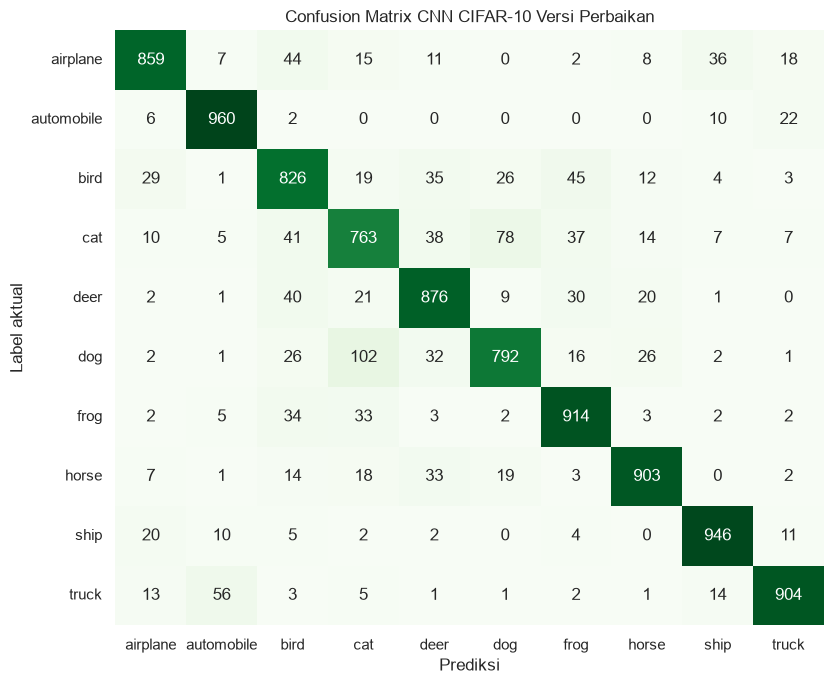

,Kelas,Akurasi baseline,Akurasi perbaikan,Selisih
1,automobile,0.792,0.960,0.168
8,ship,0.834,0.946,0.112
6,frog,0.848,0.914,0.066
9,truck,0.631,0.904,0.273
7,horse,0.699,0.903,0.204
4,deer,0.622,0.876,0.254
0,airplane,0.673,0.859,0.186
2,bird,0.518,0.826,0.308
5,dog,0.544,0.792,0.248
3,cat,0.479,0.763,0.284


AUC macro CIFAR-10 versi perbaikan: 0.9901


In [ ]:
proba_v2 = tf.nn.softmax(model_v2.predict(test_images, verbose=0)).numpy()
pred_v2 = proba_v2.argmax(axis=1)

cm_v2 = plot_confusion(test_labels.ravel(), pred_v2, class_names,
                       'Confusion Matrix CNN CIFAR-10 Versi Perbaikan',
                       figsize=(8.5, 7), cmap='Greens')

akurasi_kelas_v2 = cm_v2.diagonal() / cm_v2.sum(axis=1)
tabel_v2 = pd.DataFrame({
    'Kelas': class_names,
    'Akurasi baseline': akurasi_kelas,
    'Akurasi perbaikan': akurasi_kelas_v2,
    'Selisih': akurasi_kelas_v2 - akurasi_kelas,
}).sort_values('Akurasi perbaikan', ascending=False)
display(tabel_v2.round(4))

auc_macro_cifar = roc_auc_score(test_labels.ravel(), proba_v2,
                                multi_class='ovr', average='macro')
print(f'AUC macro CIFAR-10 versi perbaikan: {auc_macro_cifar:.4f}')

Bentuk bobot konvolusi pertama: (3, 3, 3, 32)


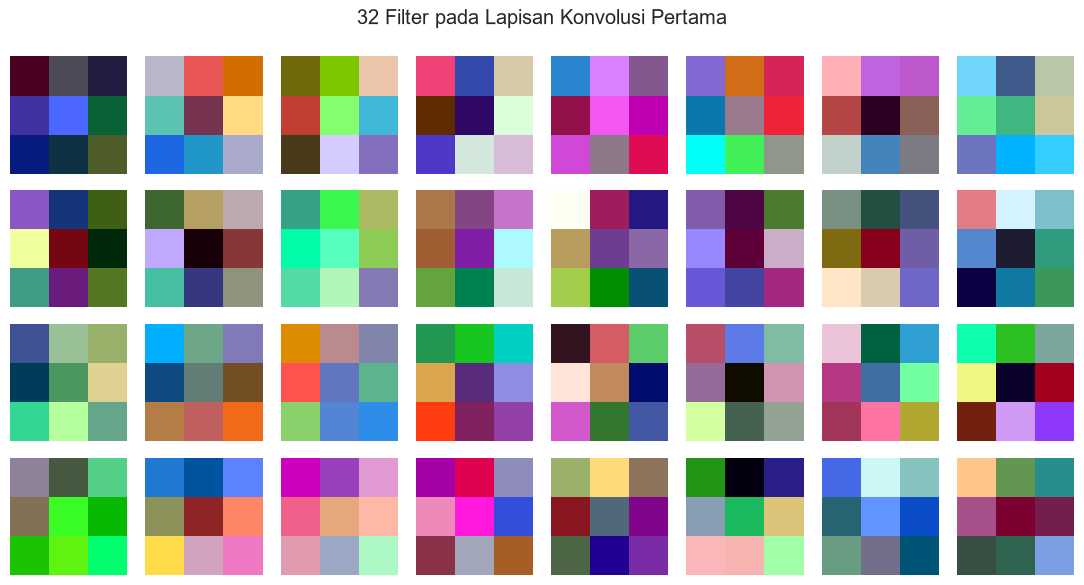

In [ ]:
# Visualisasi filter yang dipelajari pada lapisan konvolusi pertama
lapisan_konv1 = None
for lapisan in model_v2.layers:
    if isinstance(lapisan, layers.Conv2D):
        lapisan_konv1 = lapisan
        break

bobot = lapisan_konv1.get_weights()[0]
print('Bentuk bobot konvolusi pertama:', bobot.shape)

def normalisasi(x):
    return (x - x.min()) / (x.max() - x.min() + 1e-8)

fig, ax = plt.subplots(4, 8, figsize=(11, 6))
for i, axi in enumerate(ax.flat):
    axi.imshow(normalisasi(bobot[:, :, :, i]))
    axi.axis('off')
plt.suptitle('32 Filter pada Lapisan Konvolusi Pertama')
plt.tight_layout()
plt.show()

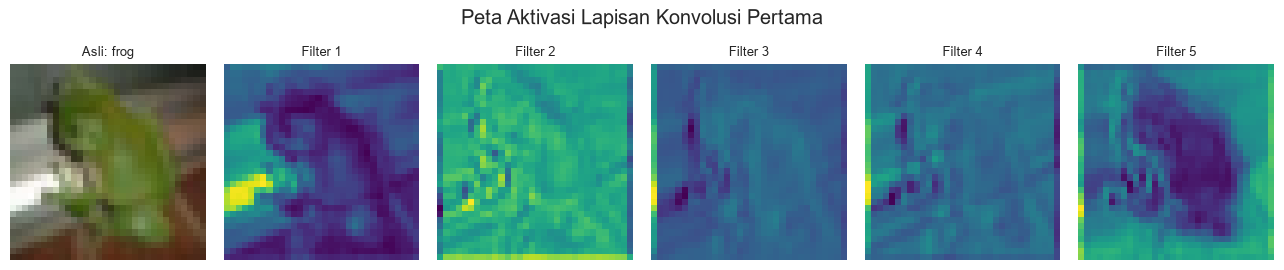

In [ ]:
# Peta aktivasi untuk satu citra uji
idx = 7
citra = test_images[idx:idx + 1]
label_asli = class_names[int(test_labels[idx][0])]

ekstraktor = keras.Model(
    inputs=model_v2.inputs,
    outputs=[l.output for l in model_v2.layers if isinstance(l, layers.Conv2D)][0],
)
aktivasi = ekstraktor.predict(citra, verbose=0)[0]

fig, ax = plt.subplots(1, 6, figsize=(13, 2.8))
ax[0].imshow(citra[0])
ax[0].set_title(f'Asli: {label_asli}', fontsize=9)
ax[0].axis('off')
for i in range(5):
    ax[i + 1].imshow(normalisasi(aktivasi[:, :, i]), cmap='viridis')
    ax[i + 1].set_title(f'Filter {i + 1}', fontsize=9)
    ax[i + 1].axis('off')
plt.suptitle('Peta Aktivasi Lapisan Konvolusi Pertama')
plt.tight_layout()
plt.show()

In [ ]:
ringkasan_cifar = pd.DataFrame([
    {'Model': 'Baseline (jobsheet)',
     'Jumlah parameter': model.count_params(),
     'Epoch': len(hist_cifar.history['loss']),
     'Akurasi latih': hist_cifar.history['accuracy'][-1],
     'Akurasi uji': test_acc,
     'Waktu (s)': waktu_cifar},
    {'Model': 'Perbaikan (BN + augmentasi + dropout)',
     'Jumlah parameter': model_v2.count_params(),
     'Epoch': len(hist_v2.history['loss']),
     'Akurasi latih': hist_v2.history['accuracy'][-1],
     'Akurasi uji': acc_v2,
     'Waktu (s)': waktu_v2},
])
display(ringkasan_cifar.round(4))

,Model,Jumlah parameter,Epoch,Akurasi latih,Akurasi uji,Waktu (s)
0,Baseline (jobsheet),122570,10,0.8020,0.6640,128.0673
1,Perbaikan (BN + augmentasi + dropout),551914,30,0.8916,0.8743,1780.6749


## Pembahasan Tugas 1

Akurasi uji naik dari 0.6640 menjadi 0.8743, sedangkan loss turun dari 1.1263 menjadi 0.3966. Target di atas 80 persen tercapai.

Batch normalization yang paling berpengaruh. Tanpa BN, skala aktivasi di lapisan awal tidak stabil sehingga pelatihan lambat. Padding same juga membantu karena pada citra 32 x 32 setiap konvolusi tanpa padding memotong satu piksel di tiap sisi. Selisih akurasi latih dan uji turun dari 0.1380 menjadi 0.0173, jadi augmentasi dan dropout cukup efektif menekan overfitting.

Hampir semua kelas naik. Bird naik 0.308 (0.518 ke 0.826), cat naik 0.284 (0.479 ke 0.763), dan truck naik 0.273 (0.631 ke 0.904). Kenaikan terkecil ada pada frog dan ship yang sejak awal sudah tinggi. Cat masih jadi kelas terendah dengan 0.763, diikuti dog 0.792 dan bird 0.826. AUC macro 0.9901 menunjukkan pemisahan antar kelas sudah baik meskipun akurasinya belum setinggi itu.

## Interpretasi Filter dan Peta Aktivasi

Filter lapisan pertama menangkap tepi dengan berbagai arah, gradasi warna, dan tekstur halus. Peta aktivasi menunjukkan bagian citra yang paling kuat merespons filter tertentu, misalnya tepi objek atau batas antara objek dan latar. Ini sesuai dengan sifat CNN yang mempelajari fitur bertingkat.


# Tugas Praktikum - CNN untuk MNIST

MNIST berisi 70.000 citra angka tulisan tangan 28 x 28 piksel dengan 10 kelas.

## Langkah 1: Memuat Data

Nilai piksel dinormalisasi ke 0 sampai 1 dan diberi satu kanal warna supaya sesuai input Conv2D.


In [ ]:
(x_train_m, y_train_m), (x_test_m, y_test_m) = keras.datasets.mnist.load_data()

x_train_m = (x_train_m / 255.0).astype('float32')[..., np.newaxis]
x_test_m = (x_test_m / 255.0).astype('float32')[..., np.newaxis]

print('Bentuk data latih:', x_train_m.shape)
print('Bentuk data uji  :', x_test_m.shape)
print('Jumlah kelas     :', len(np.unique(y_train_m)))

Bentuk data latih: (60000, 28, 28, 1)
Bentuk data uji  : (10000, 28, 28, 1)
Jumlah kelas     : 10


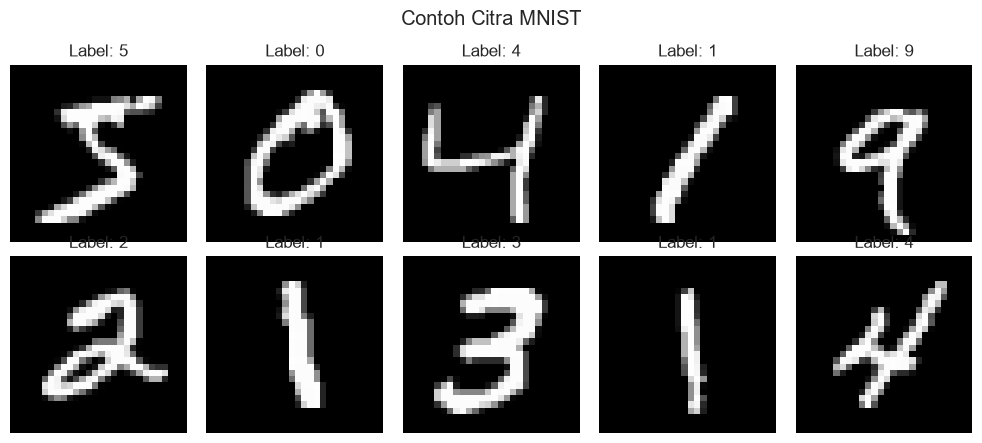

In [ ]:
plt.figure(figsize=(10, 4.5))
for i in range(10):
    ax = plt.subplot(2, 5, i + 1)
    plt.imshow(x_train_m[i].squeeze(), cmap='gray')
    plt.title(f'Label: {y_train_m[i]}')
    plt.axis('off')
plt.suptitle('Contoh Citra MNIST')
plt.tight_layout()
plt.show()

## Langkah 2: Membangun Model CNN

Tiga lapisan konvolusi 32, 64, dan 64 dengan dua max pooling, lalu global average pooling, dense 64, dropout 0.4, dan dense 10 dengan softmax. Loss yang dipakai sparse categorical crossentropy karena labelnya berupa indeks kelas.


In [ ]:
def buat_model_mnist():
    tf.keras.utils.set_random_seed(SEED)
    model = keras.Sequential([
        keras.Input(shape=(28, 28, 1)),
        layers.Conv2D(32, 3, activation='relu'),
        layers.MaxPool2D(2, 2),
        layers.Conv2D(64, 3, activation='relu'),
        layers.MaxPool2D(2, 2),
        layers.Conv2D(64, 3, activation='relu'),
        layers.GlobalAveragePooling2D(),
        layers.Dense(64, activation='relu'),
        layers.Dropout(0.4),
        layers.Dense(10, activation='softmax'),
    ], name='cnn_mnist')
    model.compile(optimizer='adam',
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])
    return model


model_mnist = buat_model_mnist()
model_mnist.summary()

Model: "cnn_mnist"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_19 (Conv2D)              │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_13 (MaxPooling2D) │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_20 (Conv2D)              │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_14 (MaxPooling2D) │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_21 (Conv2D)              │ (None, 3, 3, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 60,554 (236.54 KB)

 Trainable params: 60,554 (236.54 KB)

 Non-trainable params: 0 (0.00 B)

## Langkah 3: Melatih Model

Pelatihan 8 epoch dengan batch size 128 dan 10 persen data latih dipakai sebagai validasi. Early stopping dipasang sebagai pengaman.


In [ ]:
def latih_mnist():
    callback = [
        keras.callbacks.EarlyStopping(monitor='val_accuracy', patience=3,
                                      restore_best_weights=True),
    ]
    h = model_mnist.fit(x_train_m, y_train_m,
                        epochs=8, batch_size=128,
                        validation_split=0.1,
                        callbacks=callback, verbose=2)
    return h


hist_mnist, waktu_mnist = hitung_waktu(latih_mnist)
print(f'Waktu pelatihan: {waktu_mnist:.1f} detik')

Epoch 1/8


422/422 - 8s - 19ms/step - accuracy: 0.7608 - loss: 0.7223 - val_accuracy: 0.9535 - val_loss: 0.1628


Epoch 2/8


422/422 - 6s - 15ms/step - accuracy: 0.9296 - loss: 0.2403 - val_accuracy: 0.9617 - val_loss: 0.1182


Epoch 3/8


422/422 - 6s - 15ms/step - accuracy: 0.9463 - loss: 0.1812 - val_accuracy: 0.9743 - val_loss: 0.0824


... (7 outputs left out)

422/422 - 6s - 15ms/step - accuracy: 0.9742 - loss: 0.0889 - val_accuracy: 0.9840 - val_loss: 0.0528


Epoch 8/8


422/422 - 6s - 15ms/step - accuracy: 0.9745 - loss: 0.0884 - val_accuracy: 0.9872 - val_loss: 0.0429


Waktu pelatihan: 52.8 detik


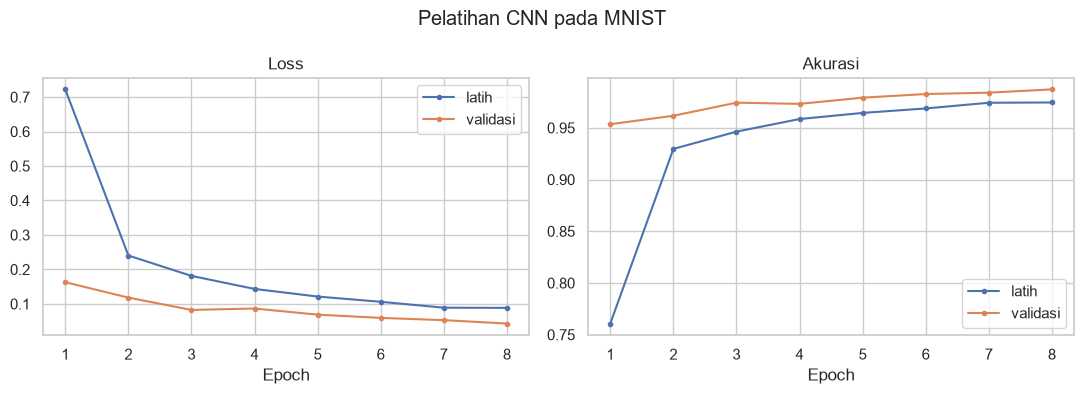

In [ ]:
plot_history(hist_mnist.history, 'Pelatihan CNN pada MNIST')

## Langkah 4: Evaluasi Model

Evaluasi memakai 10.000 citra uji yang tidak dipakai saat pelatihan.


In [ ]:
loss_mnist, acc_mnist = model_mnist.evaluate(x_test_m, y_test_m, verbose=0)
print(f'Loss data uji    : {loss_mnist:.4f}')
print(f'Akurasi data uji : {acc_mnist:.4f}')

proba_mnist = model_mnist.predict(x_test_m, verbose=0)
pred_mnist = proba_mnist.argmax(axis=1)

print()
print(classification_report(y_test_m, pred_mnist, digits=4))

Loss data uji    : 0.0399
Akurasi data uji : 0.9874



              precision    recall  f1-score   support

           0     0.9918    0.9918    0.9918       980
           1     0.9921    0.9982    0.9952      1135
           2     0.9901    0.9738    0.9819      1032
           3     0.9881    0.9871    0.9876      1010
           4     0.9959    0.9868    0.9913       982
           5     0.9683    0.9933    0.9806       892
           6     0.9958    0.9812    0.9884       958
           7     0.9751    0.9912    0.9831      1028
           8     0.9938    0.9856    0.9897       974
           9     0.9822    0.9841    0.9832      1009

    accuracy                         0.9874     10000
   macro avg     0.9873    0.9873    0.9873     10000
weighted avg     0.9875    0.9874    0.9874     10000



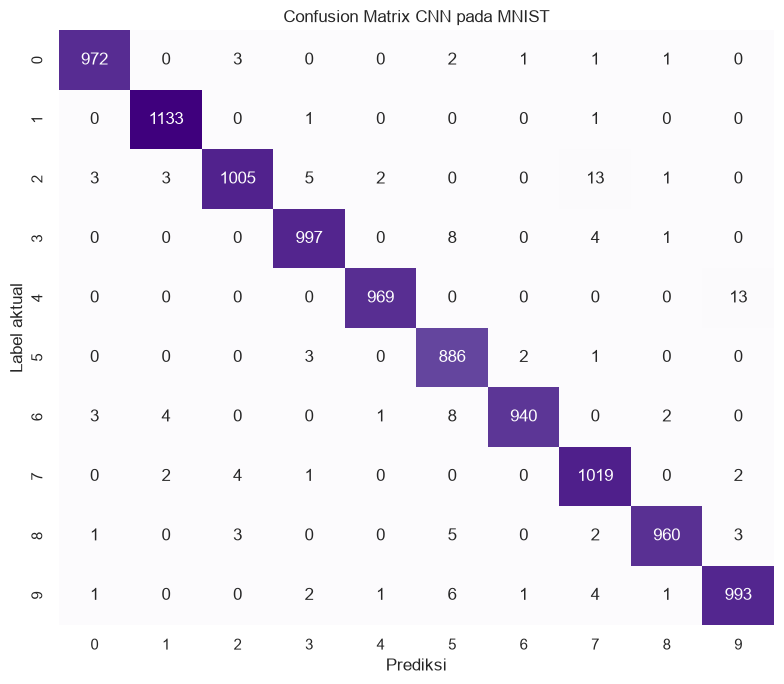

Prediksi benar: 9874 dari 10000 (0.9874)
Prediksi salah: 126


In [ ]:
cm_mnist = plot_confusion(y_test_m, pred_mnist, [str(i) for i in range(10)],
                          'Confusion Matrix CNN pada MNIST',
                          figsize=(8, 7), cmap='Purples')

benar = np.trace(cm_mnist)
total = cm_mnist.sum()
print(f'Prediksi benar: {benar} dari {total} ({benar / total:.4f})')
print(f'Prediksi salah: {total - benar}')

In [ ]:
# Angka yang paling sering tertukar
salinan = cm_mnist.copy()
np.fill_diagonal(salinan, 0)

pasangan = [{'Aktual': i, 'Prediksi': j, 'Jumlah': int(salinan[i, j])}
            for i in range(10) for j in range(10) if i != j and salinan[i, j] > 0]

tabel_pasangan = pd.DataFrame(pasangan).sort_values('Jumlah', ascending=False)
print('Lima pasangan paling sering tertukar:')
display(tabel_pasangan.head(5).reset_index(drop=True))

akurasi_per_angka = pd.DataFrame({
    'Angka': list(range(10)),
    'Akurasi': cm_mnist.diagonal() / cm_mnist.sum(axis=1),
    'Recall': cm_mnist.diagonal() / cm_mnist.sum(axis=1),
    'Jumlah uji': cm_mnist.sum(axis=1),
})
display(akurasi_per_angka.round(4))

Lima pasangan paling sering tertukar:


,Aktual,Prediksi,Jumlah
0,2,7,13
1,4,9,13
2,3,5,8
3,6,5,8
4,9,5,6


,Angka,Akurasi,Recall,Jumlah uji
0,0,0.9918,0.9918,980
1,1,0.9982,0.9982,1135
2,2,0.9738,0.9738,1032
3,3,0.9871,0.9871,1010
4,4,0.9868,0.9868,982
5,5,0.9933,0.9933,892
6,6,0.9812,0.9812,958
7,7,0.9912,0.9912,1028
8,8,0.9856,0.9856,974
9,9,0.9841,0.9841,1009


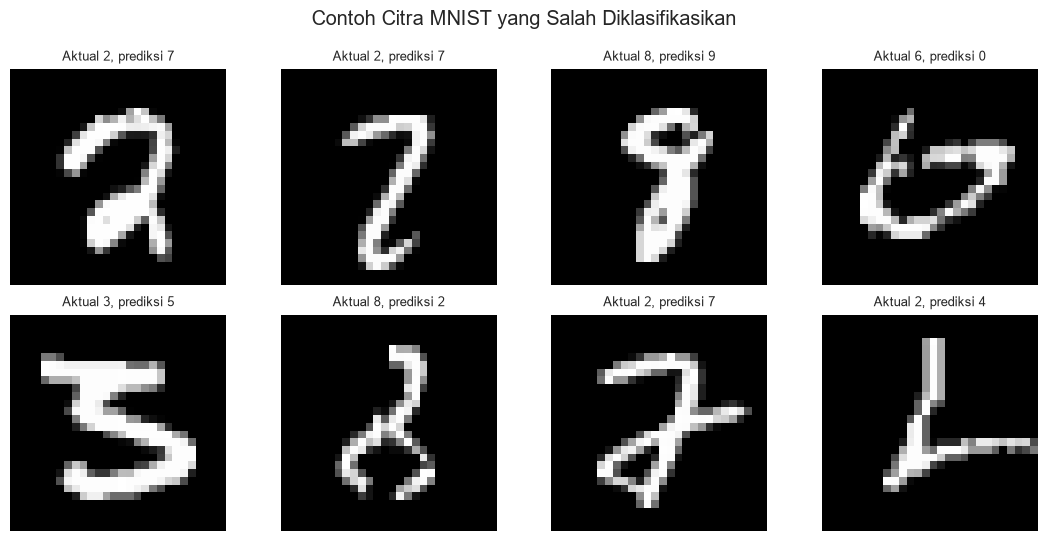

In [ ]:
idx_salah = np.where(pred_mnist != y_test_m)[0][:8]

fig, ax = plt.subplots(2, 4, figsize=(11, 5.5))
for i, axi in enumerate(ax.flat):
    idx = idx_salah[i]
    axi.imshow(x_test_m[idx].squeeze(), cmap='gray')
    axi.set_title(f'Aktual {y_test_m[idx]}, prediksi {pred_mnist[idx]}', fontsize=9)
    axi.axis('off')
plt.suptitle('Contoh Citra MNIST yang Salah Diklasifikasikan')
plt.tight_layout()
plt.show()

,Model,Jumlah parameter,Akurasi uji,Kenaikan akurasi
0,"ANN (JS13, 128-64)",109386,0.9688,0.0000
1,CNN (JS14),60554,0.9874,0.0186


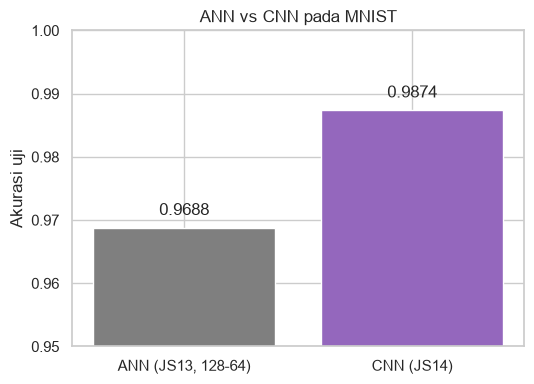

In [ ]:
# Perbandingan dengan hasil ANN pada JS13
hasil_ann_js13 = 0.9688  # akurasi uji ANN 2 hidden layer (128, 64) dari JS13

tabel_mnist = pd.DataFrame([
    {'Model': 'ANN (JS13, 128-64)', 'Jumlah parameter': 109386,
     'Akurasi uji': hasil_ann_js13},
    {'Model': 'CNN (JS14)', 'Jumlah parameter': model_mnist.count_params(),
     'Akurasi uji': acc_mnist},
])
tabel_mnist['Kenaikan akurasi'] = tabel_mnist['Akurasi uji'] - hasil_ann_js13
display(tabel_mnist.round(4))

plt.figure(figsize=(5.5, 4))
plt.bar(tabel_mnist['Model'], tabel_mnist['Akurasi uji'], color=['tab:gray', 'tab:purple'])
plt.ylim(0.95, 1.0)
plt.ylabel('Akurasi uji')
plt.title('ANN vs CNN pada MNIST')
for i, v in enumerate(tabel_mnist['Akurasi uji']):
    plt.text(i, v + 0.002, f'{v:.4f}', ha='center')
plt.tight_layout()
plt.show()

## Pembahasan

Akurasi data uji 0.9874 dengan 60.554 parameter. Sebagai pembanding, ANN dua hidden layer pada JS13 mendapat 0.9688 dengan 109.386 parameter, jadi CNN lebih akurat sekaligus lebih ringan. Penyebabnya weight sharing: satu filter 3 x 3 hanya punya 9 bobot yang dipakai di semua posisi citra, sehingga hubungan antar piksel bertetangga tetap dipertahankan tanpa menambah banyak parameter.

Dari 10.000 citra uji, 126 salah. Angka 1 paling mudah dikenali (0.9982) dan angka 2 paling sering keliru (0.9738). Pasangan yang paling sering tertukar adalah 2 diprediksi 7 dan 4 diprediksi 9, masing-masing 13 kasus, lalu 3 diprediksi 5 dan 6 diprediksi 5 masing-masing 8 kasus, serta 9 diprediksi 5 sebanyak 6 kasus. Bentuk 4 yang terbuka memang mirip 9, dan 2 yang dasarnya tidak menutup mirip 7.

Pelatihan hanya butuh sekitar 53 detik untuk 8 epoch karena citra MNIST kecil dan hanya satu kanal.


# Kesimpulan

CNN bisa mengekstraksi fitur sendiri lewat kernel yang dipelajari saat pelatihan, jadi tidak perlu ekstraksi fitur manual seperti pada ANN. Lapisan awal menangkap tepi dan warna, lapisan tengah menangkap tekstur, dan lapisan akhir menangkap bentuk objek.

Weight sharing membuat jumlah parameter jauh lebih kecil. Pada MNIST, CNN dengan 60.554 parameter mengalahkan ANN dengan 109.386 parameter.

Pada Cat vs Dog, akurasi uji 0.8045 sudah cukup baik untuk dataset dua kelas beresolusi 64 x 64. Pada CIFAR-10, akurasi baseline 0.6640 naik menjadi 0.8743 setelah ditambah batch normalization, padding same, augmentasi, dan dropout.

## Hasil Akhir

| Model | Parameter | Akurasi latih | Akurasi uji |
|---|---|---|---|
| CNN Cat vs Dog (jobsheet) | 813.217 | 0.8496 | 0.8045 |
| CNN CIFAR-10 (jobsheet) | 122.570 | 0.8020 | 0.6640 |
| CNN CIFAR-10 (modifikasi) | 551.914 | 0.8916 | 0.8743 |
| CNN MNIST | 60.554 | 0.9745 | 0.9874 |
